# Titanic Survival Prediction
### Exploring passenger data with Logistic Regression and a few useful ML comparisons

This notebook builds on my original Titanic classification practical. I have kept the main ideas and workflow—exploring the data, checking missing values, preparing features, fitting Logistic Regression, and comparing it with other classifiers—while making the analysis easier to follow and more reliable.

**Question:** Can we use passenger information to predict whether someone survived the Titanic disaster?

This is a learning project, not a claim that a model can explain a human tragedy. The data gives us patterns to study; it does not tell the whole story.

## 1. What this notebook covers

- Loading and inspecting the Titanic passenger dataset.
- Exploring survival rates and missing values.
- Preparing numerical and categorical features.
- Train/test split the data before fitting preprocessing steps.
- Fitting Logistic Regression and comparing it with K-Nearest Neighbours, Gaussian Naive Bayes, and a Decision Tree.
- I Evaluated models using accuracy, precision, recall, F1-score, confusion matrices, and ROC-AUC.
- Inspected feature importance from the Decision Tree.


## 2. Imports and display settings

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)
RANDOM_STATE = 42

## 3. Load the data


In [2]:
DATA_PATH = "Titanic-Dataset.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


## 4. First look at the data

The target variable is `Survived`:
- `0` = did not survive
- `1` = survived

`PassengerId`, `Name`, `Ticket`, and `Cabin` are excluded from this first modelling exercise. Some may contain information worth extracting in a more advanced project, but they are not used as raw predictors here.

In [3]:
display(df.info())
display(df.describe(include="all").T)
display(df["Survived"].value_counts().rename(index={0: "Did not survive", 1: "Survived"}))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.000,NaN,NaN,NaN,446.000,257.354,1.000,223.500,446.000,668.500,891.000
Survived,891.000,NaN,NaN,NaN,0.384,0.487,0.000,0.000,0.000,1.000,1.000
Pclass,891.000,NaN,NaN,NaN,2.309,0.836,1.000,2.000,3.000,3.000,3.000
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.000,NaN,NaN,NaN,29.699,14.526,0.420,20.125,28.000,38.000,80.000
SibSp,891.000,NaN,NaN,NaN,0.523,1.103,0.000,0.000,0.000,1.000,8.000
Parch,891.000,NaN,NaN,NaN,0.382,0.806,0.000,0.000,0.000,0.000,6.000
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.000,NaN,NaN,NaN,32.204,49.693,0.000,7.910,14.454,31.000,512.329


Survived
Did not survive    549
Survived           342
Name: count, dtype: int64

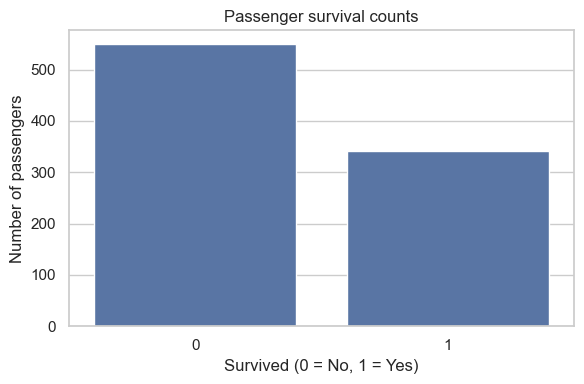

In [4]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Survived")
ax.set_title("Passenger survival counts")
ax.set_xlabel("Survived (0 = No, 1 = Yes)")
ax.set_ylabel("Number of passengers")
plt.tight_layout()
plt.show()

## 5. Missing-value check

Before filling anything, I saw where the gaps are because `Age` and `Cabin` are particularly incomplete in this dataset; `Embarked` also has a small number of missing values.

In [5]:
missing_summary = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Missing (%)", ascending=False)

display(missing_summary)

,Missing values,Missing (%)
Cabin,687,77.100
Age,177,19.870
Embarked,2,0.220
PassengerId,0,0.000
Survived,0,0.000
Pclass,0,0.000
Name,0,0.000
Sex,0,0.000
SibSp,0,0.000
Parch,0,0.000


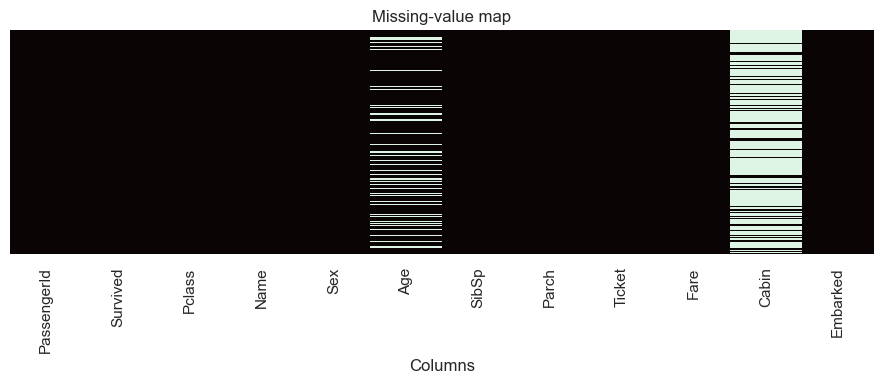

In [6]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="mako")
plt.title("Missing-value map")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()

### A quick look at Age
Instead of filling missing values manually on the full dataset, the modelling pipeline will learn the median from the training data only.

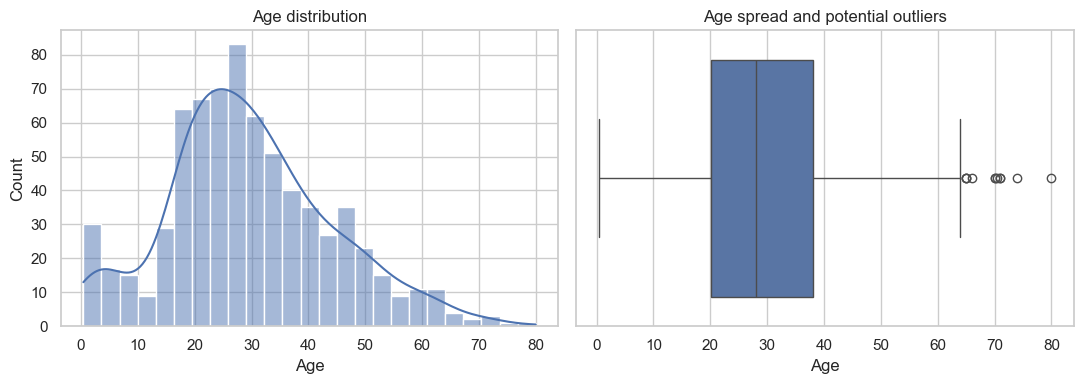

Age skewness: 0.389


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Age"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Age distribution")
sns.boxplot(x=df["Age"], ax=axes[1])
axes[1].set_title("Age spread and potential outliers")
plt.tight_layout()
plt.show()

print("Age skewness:", round(df["Age"].skew(), 3))

## 6. Feature selection and train/test split

We separate the target (`Survived`) from the predictors. The split is stratified so that the survival proportion is approximately maintained in both sets.

The test set is held back until evaluation.

In [8]:
target = "Survived"
drop_columns = ["PassengerId", "Name", "Ticket", "Cabin"]

X = df.drop(columns=[target] + drop_columns)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename("proportion"))

Training features: (712, 7)
Testing features: (179, 7)

Training target proportions:


Survived
0   0.617
1   0.383
Name: proportion, dtype: float64

## 7. Preprocessing

`Pclass` is treated as categorical for this analysis. Numerical columns are median-imputed and standardised; categorical columns are filled with their most frequent value and one-hot encoded.

All preprocessing is inside a `ColumnTransformer` and `Pipeline`. This helps prevent data leakage and keeps the same transformations consistent across training and test data.

In [9]:
X_train = X_train.copy()
X_test = X_test.copy()

for frame in (X_train, X_test):
    frame["Pclass"] = frame["Pclass"].astype("object")

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'SibSp', 'Parch', 'Fare']
Categorical features: ['Pclass', 'Sex', 'Embarked']


## 8. Logistic Regression

Logistic Regression estimates the probability of belonging to a class. Here, the model estimates the probability that a passenger survived. A default threshold of 0.5 converts probabilities into predicted classes.

The model below is fitted through a pipeline, so preprocessing is learned from the training data only.

In [10]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, logistic_predictions, target_names=["Did not survive", "Survived"]))

                 precision    recall  f1-score   support

Did not survive       0.81      0.88      0.84       110
       Survived       0.78      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.79      0.77      0.78       179
   weighted avg       0.80      0.80      0.80       179



### Logistic Regression: confusion matrix and ROC curve

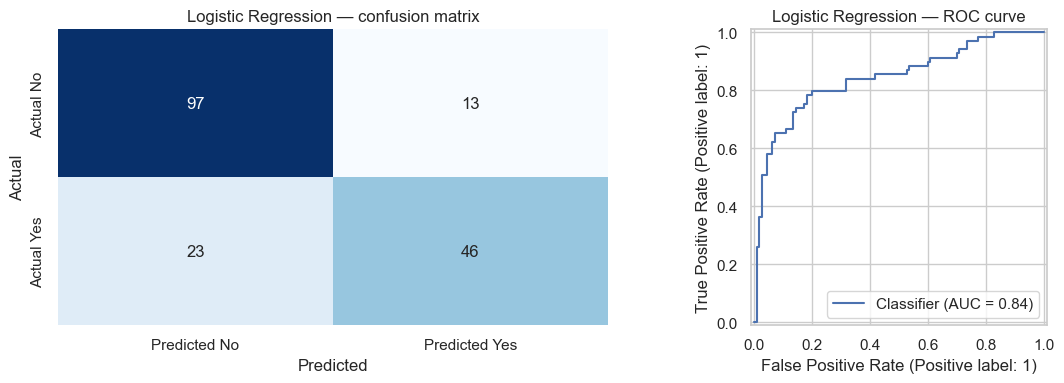

ROC-AUC: 0.844


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

Confusion = confusion_matrix(y_test, logistic_predictions)
sns.heatmap(
    Confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)
axes[0].set_title("Logistic Regression — confusion matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

RocCurveDisplay.from_predictions(y_test, logistic_probabilities, ax=axes[1])
axes[1].set_title("Logistic Regression — ROC curve")

plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc_score(y_test, logistic_probabilities), 3))

## 9. Compare with other classifiers

- **KNN:** predicts using nearby observations. Scaling matters because it relies on distances.
- **Gaussian Naive Bayes:** applies Bayes' theorem with a conditional-independence assumption and Gaussian likelihoods for numerical features.
- **Decision Tree:** learns a sequence of feature-based splits. It is easier to visualise, but can overfit if allowed to grow without control.

In [12]:
models = {
    "Logistic Regression": logistic_model,
    "K-Nearest Neighbours": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=5, metric="euclidean"))
    ]),
    "Gaussian Naive Bayes": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", GaussianNB())
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE
        ))
    ])
}

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("F1-score", ascending=False)
display(results_df.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
K-Nearest Neighbours,0.816,0.810,0.681,0.740,0.838
Logistic Regression,0.799,0.780,0.667,0.719,0.844
Gaussian Naive Bayes,0.788,0.754,0.667,0.708,0.806
Decision Tree,0.777,0.809,0.551,0.655,0.829


### Compare ROC curves

ROC curves show how the true-positive rate changes against the false-positive rate across classification thresholds. AUC summarises the curve: higher values indicate stronger ranking ability on this test set.

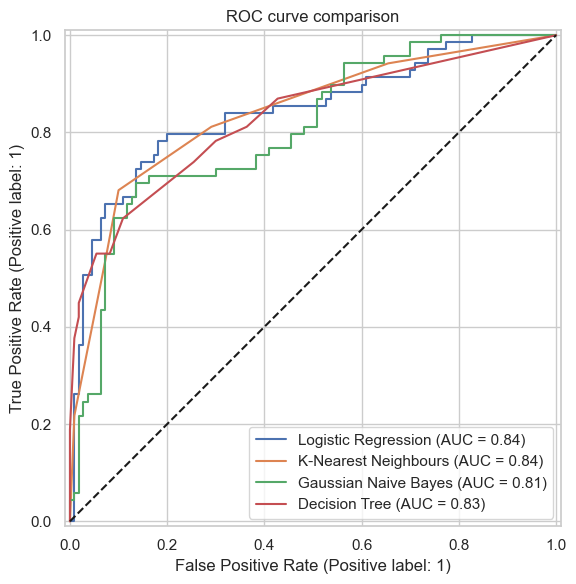

In [13]:
plt.figure(figsize=(8, 6))
for name, model in fitted_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(
        y_test, probabilities, name=name, ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.title("ROC curve comparison")
plt.tight_layout()
plt.show()

## 10. Decision Tree: feature importance

Feature importance provides one view of which transformed features the fitted tree used most when making splits. It is useful for exploration, but it should not be interpreted as proof of causation or as a complete explanation of the model.

,Importance
categorical__Sex_male,0.595
categorical__Pclass_3,0.153
numeric__Age,0.113
numeric__Fare,0.076
categorical__Embarked_S,0.038
numeric__Parch,0.025
numeric__SibSp,0.000
categorical__Pclass_2,0.000
categorical__Embarked_Q,0.000


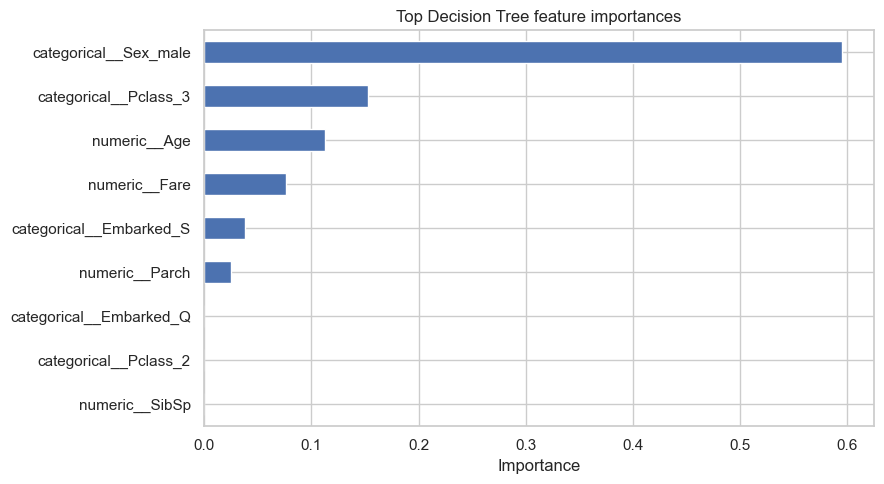

In [14]:
tree_pipeline = fitted_models["Decision Tree"]
tree_classifier = tree_pipeline.named_steps["classifier"]
feature_names = tree_pipeline.named_steps["preprocessor"].get_feature_names_out()

feature_importance = (
    pd.Series(tree_classifier.feature_importances_, index=feature_names)
    .sort_values(ascending=False)
)

display(feature_importance.head(12).to_frame("Importance"))

plt.figure(figsize=(9, 5))
feature_importance.head(12).sort_values().plot(kind="barh")
plt.title("Top Decision Tree feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 11. Outliers Detected 

A value being far from the middle does not automatically mean it is an error. Removing rows from the full dataset before splitting can also change the class balance and make evaluation less representative. If outlier treatment is needed, it should be justified and fitted using training data only.

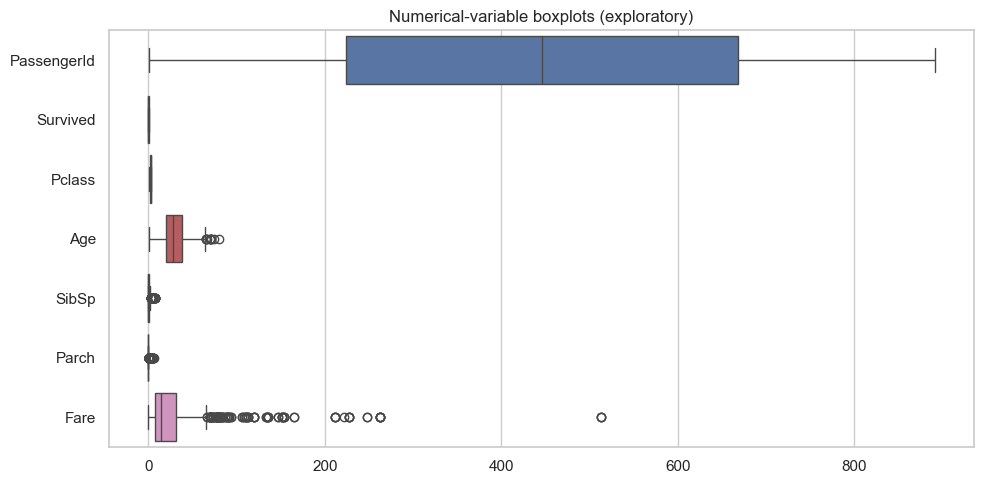

In [15]:
numeric_view = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 5))
sns.boxplot(data=numeric_view, orient="h")
plt.title("Numerical-variable boxplots (exploratory)")
plt.tight_layout()
plt.show()

## 12. Key takeaways

- Logistic Regression provides a useful baseline for this binary classification problem.
- KNN, Gaussian Naive Bayes, and Decision Tree offer different modelling assumptions and comparison points.
- Accuracy alone is not enough; precision, recall, F1-score, and ROC-AUC add useful context.
- Missing-value handling, scaling, and encoding should be learned from training data—not the full dataset.
- A model's performance is specific to this dataset and this train/test split. It should not be treated as a universal prediction of survival.
